In [1]:
import ee
import geemap.core as geemap
import pandas as pd
import matplotlib.pyplot as plt

# Authentication

In [2]:
# ee.Authenticate()  # Run once
ee.Initialize(project="eo-toolkit-513110")

# Map

In [3]:
# Load climate data for a given period and display its metadata.
jan_2023_climate = (
    ee.ImageCollection('ECMWF/ERA5_LAND/MONTHLY_AGGR')
    .filterDate('2023-01', '2023-02')
    .first()
)
# jan_2023_climate

In [4]:
# Instantiate a map object and add the temperature band as a layer with specific visualization properties.
m = geemap.Map(center=[30, 0], zoom=2)

viz_params = {
    "bands": ["temperature_2m"],
    "min": 229,
    "max": 304,
    "palette": "inferno",
}
m.add_layer(jan_2023_climate, viz_params, "Temperature (K)")

In [5]:
# Display the map
m

Map(center=[30, 0], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', trans…

# Temperature (°C), Precipitations (mm), Wind (m/h)

In [6]:
# Function to extract values for a single image at our point
def extract_point_data(image):
    stats = image.reduceRegion(
        reducer=ee.Reducer.first(),
        geometry=point,
        scale=11132,
        maxPixels=1e9
    )
    # Return a feature with the properties and timestamp
    return ee.Feature(None, stats).set('date', image.date().format('YYYY-MM-dd'))

In [7]:
# Define point coordinate and time window
point = ee.Geometry.Point([-0.9474, 46.9920])  # Mortagne-sur-Sèvre
start_date = "2022-09-01"
end_date = "2026-08-31"

# ERA5-Land Daily Aggregated collection (active up to present)
bands = [
    "temperature_2m",
    "total_precipitation_sum",
    "u_component_of_wind_10m",
    "v_component_of_wind_10m"
]

era5_daily = (
    ee.ImageCollection("ECMWF/ERA5_LAND/DAILY_AGGR")
    .filterDate(start_date, end_date)
    .select(bands)
)

# Map the extraction across the entire collection server-side
time_series_fc = ee.FeatureCollection(era5_daily.map(extract_point_data))

# Pull the lightweight feature collection to client-side
data_list = time_series_fc.getInfo()['features']

# Parse into a clean Pandas DataFrame
records = []
for feat in data_list:
    props = feat['properties']
    records.append({
        'date': props.get('date'),
        'temperature_2m': props.get('temperature_2m'),
        'total_precipitation_sum': props.get('total_precipitation_sum'),
        'u_component_of_wind_10m': props.get('u_component_of_wind_10m'),
        'v_component_of_wind_10m': props.get('v_component_of_wind_10m'),
    })

df = pd.DataFrame(records)

# Clean data, convert units, and sort
df['date'] = pd.to_datetime(df['date'])
df['mean_2m_air_temperature'] = pd.to_numeric(df['temperature_2m']) - 273.15  # From Kelvin to Celcius
df['precipitation_mm'] = pd.to_numeric(df['total_precipitation_sum']) * 1000.0  # From Liters to Milliliters

u = pd.to_numeric(df['u_component_of_wind_10m'])
v = pd.to_numeric(df['v_component_of_wind_10m'])
df['wind_speed_ms'] = (u**2 + v**2) ** 0.5

df = df[['date', 'mean_2m_air_temperature', 'precipitation_mm', 'wind_speed_ms']].dropna()
df = df.sort_values('date').reset_index(drop=True)

In [8]:
df.head()

,date,mean_2m_air_temperature,precipitation_mm,wind_speed_ms
0,2022-09-01,20.556719,4.209828,0.629016
1,2022-09-02,19.053852,3.315170,2.137757
2,2022-09-03,18.968888,0.895160,3.130970
3,2022-09-04,20.772160,0.283943,1.902893
4,2022-09-05,21.479856,0.165704,1.264271


In [9]:
df.describe()

,date,mean_2m_air_temperature,precipitation_mm,wind_speed_ms
count,1460,1460.000000,1460.000000,1460.000000
mean,2024-08-30 12:00:00,13.410422,2.327438,3.123723
min,2022-09-01 00:00:00,-2.878744,-0.000015,0.136864
25%,2023-08-31 18:00:00,9.131631,0.008959,2.119268
50%,2024-08-30 12:00:00,12.849122,0.401501,3.005451
75%,2025-08-30 06:00:00,17.945119,2.636658,3.960718
max,2026-08-30 00:00:00,33.615952,60.419440,8.655814
std,NaN,6.401233,4.294132,1.423762


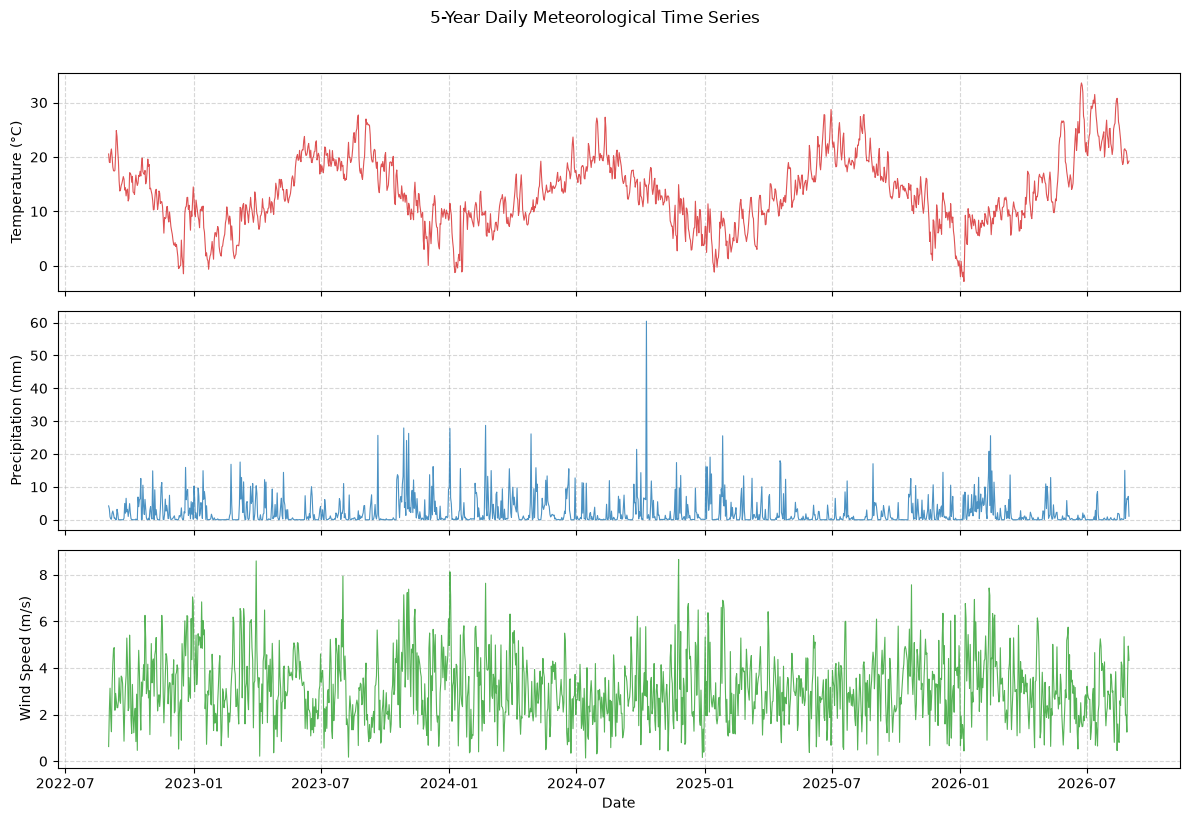

In [10]:
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

metrics = [
    ('mean_2m_air_temperature', 'Temperature (°C)', 'tab:red'),
    ('precipitation_mm', 'Precipitation (mm)', 'tab:blue'),
    ('wind_speed_ms', 'Wind Speed (m/s)', 'tab:green')
]

for ax, (col, ylabel, color) in zip(axes, metrics):
    ax.plot(df['date'], df[col], color=color, linewidth=0.8, alpha=0.8)
    ax.set_ylabel(ylabel)
    ax.grid(True, linestyle='--', alpha=0.5)

axes[-1].set_xlabel('Date')

fig.suptitle('5-Year Daily Meteorological Time Series', fontsize=12, y=1.02)
fig.subplots_adjust(top=0.92)

plt.tight_layout()
plt.show()